# The toric code in Python: how `toric` computes

The physics is best seen in the [browser app](../app/toric_code_playground.html): click edges, watch the anyons.
This notebook shows how the same calculations are done in Python with `toric`, and why each one is short.

The whole trick is one formula. Every state you can reach from a ground state with Pauli gates is

$$|\psi\rangle = i^k \, X^a Z^b \, |\text{start}\rangle ,$$

where $a$ and $b$ are bit strings with one bit per edge (where the $X$'s and the $Z$'s are) and $|\text{start}\rangle$
is a ground state with logical amplitudes $c$. So a state on 72 qubits is stored as two lists of edges, a phase and
4 numbers, and every question below (where are the anyons? what is the energy? what happened to the stored qubits?)
is answered by counting bits.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import toric

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (5.5, 3.4)})


def amps(s):
    """The 4 logical amplitudes, rounded (all real in this notebook)."""
    return np.round(s.logical().real, 3) + 0.0

## 1. A state is two strings and a phase

`new_state(L)` is a ground state of the $L \times L$ torus, $|00\rangle$ unless you pass another start
(`"+0"`, `"++"`, `"phi+"` or any 4 amplitudes). Nothing has been applied yet, so both strings are empty.

In [4]:
s = toric.new_state(6)
t = s.torus                       # the geometry: edge labels, stars, plaquettes, loops
print(s)
print("energy:", s.energy(), "  anyons (e, m):", s.anyons())

PauliState(L=6: 1 * X on [] * Z on [] |start>, start c = [1. 0. 0. 0.])
energy: -72   anyons (e, m): ([], [])


Edges are numbered: `t.h(i, j)` is the horizontal edge leaving vertex $(i, j)$ to the right, `t.v(i, j)` the
vertical one going up.

## 2. A gate flips one bit, and the anyons are the ends of the strings

`s.apply("Z", e)` flips bit $e$ of $b$. A $Z$ anticommutes with the two stars at the ends of edge $e$, so `toric`
flips a flag at each of those two vertices: those flags are the **e anyons**, and each costs energy $+2$.

In [3]:
s.apply("Z", t.h(2, 2))
print(s)
print("ends of that edge:", t.ends(t.h(2, 2)), "  e anyons:", s.anyons()[0], "  energy:", s.energy())

PauliState(L=6: 1 * X on [] * Z on [28] |start>, start c = [1. 0. 0. 0.])
ends of that edge: [(2, 2), (3, 2)]   e anyons: [(2, 2), (3, 2)]   energy: -68


Extend the string. Each new $Z$ flips the flag where the string ended (the anyon leaves) and the next one (it
arrives). A vertex inside the string is touched twice, so its flag is back to normal: **only the ends of a string
are anyons**, and the energy stays the same however long the string is.

In [4]:
s.apply_string("Z", [t.h(3, 2), t.h(4, 2)])
print(s)
print("e anyons:", s.anyons()[0], "  energy:", s.energy())

PauliState(L=6: 1 * X on [] * Z on [28, 30, 32] |start>, start c = [1. 0. 0. 0.])
e anyons: [(2, 2), (5, 2)]   energy: -68


## 3. Strings around the torus are the logical gates

Finish the row so the string closes around the torus. No ends, no anyons, ground-state energy, yet the state is not
the start state. The torus has 4 ground states $|q_1 q_2\rangle$, and a closed string acts on them as a logical gate.
To find which one, `s.windings()` counts how many times the strings cross four fixed reference loops. Each count is
one line of bit counting, for example `s.b[t.x_col(0)].sum() % 2`. Odd means that logical Pauli was applied.

In [5]:
s.apply_string("Z", [t.h(5, 2), t.h(0, 2), t.h(1, 2)])
print("anyons:", s.anyons(), "  energy:", s.energy())
print("windings:", s.windings(), "  by hand:", int(s.b[t.x_col(0)].sum() % 2))
print("logical amplitudes of |00>, |01>, |10>, |11>:", amps(s))

anyons: ([], [])   energy: -72
windings: {'X1': 0, 'X2': 0, 'Z1': 1, 'Z2': 0}   by hand: 1
logical amplitudes of |00>, |01>, |10>, |11>: [1. 0. 0. 0.]


That gate is $\bar Z_1$: a sign on the $q_1 = 1$ part. On $|00\rangle$ it changes nothing. Start from
$|{+}0\rangle$ instead and it shows. An $X$ string around the torus (an m anyon dragged around) flips a qubit.

In [6]:
s = toric.new_state(6, "+0")
s.apply_string("Z", t.z_row(2))            # Zbar_1: |+0> -> |-0>
print("Z loop along x:     ", amps(s))
s.apply_string("X", t.x_row(4))            # Xbar_2: flips q2
print("then X loop along x:", amps(s), " windings:", s.windings())

Z loop along x:      [ 0.707  0.    -0.707  0.   ]
then X loop along x: [ 0.     0.707  0.    -0.707]  windings: {'X1': 0, 'X2': 1, 'Z1': 1, 'Z2': 0}


`logical()` only exists in the ground space (it raises an error while anyons are present). To *read* a qubit the way
an experiment would, measure a $Z$ loop around the torus: `s.loop_expectation("Zx", row)` for $q_1$,
`"Zy"` for $q_2$. Every row gives the same answer, because moving a loop by one row multiplies it by plaquettes,
which are $+1$.

In [7]:
s = toric.new_state(6)
s.apply_string("X", t.x_col(2))            # Xbar_1: |00> -> |10>
print("<Z loop along x> on rows 0..5:", np.array([s.loop_expectation("Zx", r) for r in range(6)]))
print("<Z loop along y> on cols 0..5:", np.array([s.loop_expectation("Zy", c) for c in range(6)]))

<Z loop along x> on rows 0..5: [-1. -1. -1. -1. -1. -1.]
<Z loop along y> on cols 0..5: [1. 1. 1. 1. 1. 1.]


## 4. Braiding is a sign in the phase $k$

Make an m pair with one $X$, take an e around one of the m's with a small $Z$ loop, then remove the m pair with the
same $X$. When the $Z$ loop crosses the $X$ on their shared edge, `toric` moves the $Z$ past the $X$, and
$ZX = -XZ$: the phase goes from $i^0$ to $i^2 = -1$. What is left is a small closed $Z$ loop, which is a plaquette
$B_p = +1$ and does nothing, and that $-1$: the e–m braiding phase.

In [8]:
s = toric.new_state(6)
s.apply("X", t.h(1, 1))
print("m pair:          ", s)
s.apply_string("Z", t.plaquette(1, 1))
print("e around one m:  ", s)
s.apply("X", t.h(1, 1))
print("m pair removed:  ", s)
print("logical amplitudes:", amps(s))

m pair:           PauliState(L=6: 1 * X on [14] * Z on [] |start>, start c = [1. 0. 0. 0.])
e around one m:   PauliState(L=6: -1 * X on [14] * Z on [14, 15, 17, 26] |start>, start c = [1. 0. 0. 0.])
m pair removed:   PauliState(L=6: -1 * X on [] * Z on [14, 15, 17, 26] |start>, start c = [1. 0. 0. 0.])
logical amplitudes: [-1.  0.  0.  0.]


## 5. Heat and error correction, in the same bookkeeping

`thermal_sweep(s, T, rng)` gives every edge one attempted random $X$ or $Z$ on average, kept with probability
$\min(1, e^{-\Delta E/T})$: creating a pair costs $+4$, moving or removing anyons is free. Each kept error is one more
bit in $a$ or $b$. `decode(s)` pairs up the closest anyons and joins each pair by a shortest string, which puts the
state back in the ground space. The memory survived if the windings are still all zero.

In [9]:
rng = np.random.default_rng(0)
s = toric.new_state(6)
for _ in range(5):
    toric.thermal_sweep(s, 0.6, rng)
e, m = s.anyons()
print(f"after 5 sweeps at T = 0.6: {s.a.sum()} X's and {s.b.sum()} Z's,  {len(e)} e and {len(m)} m anyons")
toric.decode(s)
print("after decoding: anyons", s.anyons(), "  windings", s.windings())

after 5 sweeps at T = 0.6: 0 X's and 3 Z's,  2 e and 0 m anyons
after decoding: anyons ([], [])   windings {'X1': 0, 'X2': 0, 'Z1': 0, 'Z2': 0}


`logical_error(s)` asks whether decoding *now* would leave a non-zero winding. `memory_lifetime(L, T, N, ...)`
repeats sweep, decode every $N$ sweeps (`None`: never), check, and returns the number of sweeps until the first
logical error. Live, 10 runs each on a $6 \times 6$ torus:

In [10]:
for every, label in [(None, "no correction     "), (1, "decode every sweep")]:
    times = [toric.memory_lifetime(6, 0.6, every, 2000, rng) for _ in range(10)]
    print(f"{label}: first logical error after ~{np.mean(times):.0f} sweeps")

no correction     : first logical error after ~15 sweeps


decode every sweep: first logical error after ~215 sweeps


Full run, 200 runs per point (`python scripts/make_results.py memory_lifetimes`, a few minutes on 4 cores). Without
correction a bigger torus does not help: a logical error only ever costs the $+4$ of one pair, whatever $L$ is.
With decoding after every sweep, the lifetime grows fast with $L$.

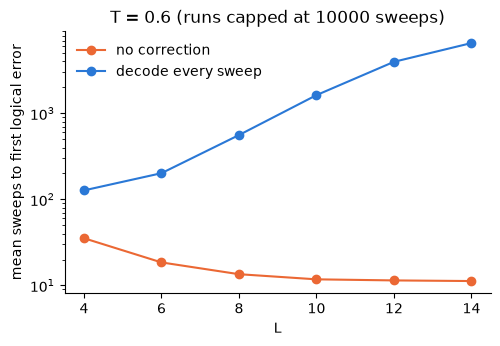

In [11]:
ml = json.loads(Path("../results/memory_lifetimes.json").read_text())
for every, color, label in [(None, ORANGE, "no correction"), (1, BLUE, "decode every sweep")]:
    pts = [p for p in ml["points"] if p["T"] == 0.6 and p["correct_every"] == every]
    plt.semilogy([p["L"] for p in pts], [p["mean"] for p in pts], "o-", color=color, label=label)
plt.xlabel("L")
plt.ylabel("mean sweeps to first logical error")
plt.title(f"T = 0.6 (runs capped at {ml['max_sweeps']} sweeps)")
plt.legend(frameon=False);

## 6. Checked against the full state vector

On a $3 \times 3$ torus (18 qubits) `toric.ExactToricCode` builds the $2^{18}$-entry state vector and applies the
same gates as matrices. The bookkeeping gives the same answers; `tests/test_code.py` checks energies, stabilizers,
amplitudes, loops and logical states this way.

In [12]:
ex = toric.ExactToricCode(3)
s, psi = toric.new_state(3, "+0"), ex.state(toric.START_STATES["+0"])
for gate, e in [("X", ex.torus.h(1, 1))] + [("Z", e) for e in ex.torus.plaquette(1, 1)] + [("X", ex.torus.h(1, 1))]:
    s.apply(gate, e)
    psi = ex.apply(gate, e, psi)
print("toric:", amps(s))
print("exact:", np.round(ex.logical_amplitudes(psi).real, 3) + 0.0)

toric: [-0.707  0.    -0.707  0.   ]
exact: [-0.707  0.    -0.707  0.   ]


## Exercises

1. Make an e pair, then move one e all the way around the torus back to its partner. Has `s.logical()` changed?
   Try again from `toric.new_state(6, "+0")`.
2. Apply $X$ on one edge. Where are the anyons now, and what kind are they (`s.anyons()` returns `(e, m)`)?
3. Take an e around an m twice. What is $k$?